<a href="https://colab.research.google.com/github/palakmirok/radar-detection-performance/blob/main/CA_CFAR_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Detected cells: [50, 100, 150]


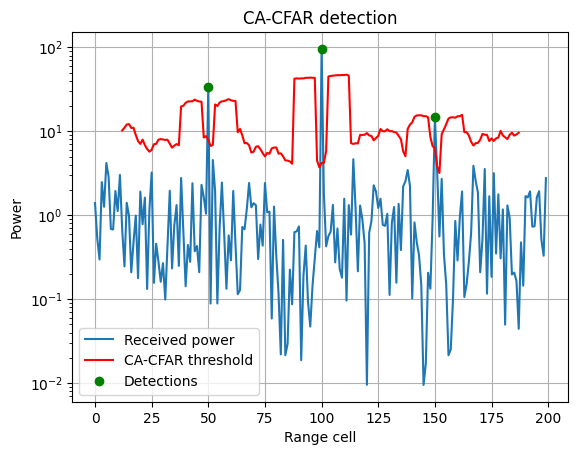

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(1)
N = 200


x = (np.random.randn(N) + 1j*np.random.randn(N)) / np.sqrt(2)


for pos, snr_db in [(50, 15), (100, 20), (150, 12)]:
    x[pos] += np.sqrt(10**(snr_db/10))

power = np.abs(x)**2


train = 10
guard = 2
pfa = 1e-3
n_train = 2*train
alpha = n_train * (pfa**(-1/n_train) - 1)   # threshold factor

threshold = np.full(N, np.nan)
detections = []

for i in range(train+guard, N-train-guard):
    left  = power[i-guard-train : i-guard]
    right = power[i+guard+1 : i+guard+train+1]
    noise_est = (left.sum() + right.sum()) / n_train   # aas-paas ka average
    threshold[i] = alpha * noise_est
    if power[i] > threshold[i]:
        detections.append(i)

print("Detected cells:", detections)

plt.semilogy(power, label='Received power')
plt.semilogy(threshold, 'r', label='CA-CFAR threshold')
plt.semilogy(detections, power[detections], 'go', label='Detections')
plt.xlabel('Range cell')
plt.ylabel('Power')
plt.title('CA-CFAR detection')
plt.legend()
plt.grid(True)
plt.show()